In [ ]:
AI Job Fraud Detection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving DataSet.csv to DataSet.csv


In [4]:
import pandas as pd

df = pd.read_csv("DataSet.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
print("Dataset shape:", df.shape)

Dataset shape: (17880, 18)


In [6]:
print("Columns:")
print(df.columns.tolist())

Columns:
['title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent', 'in_balanced_dataset']


In [7]:
print("Fraudulent distribution:")
print(df["fraudulent"].value_counts())

Fraudulent distribution:
fraudulent
f    17014
t      866
Name: count, dtype: int64


In [8]:
for i, column in enumerate(df.columns, 1):
    print(i, ":", column)

1 : title
2 : location
3 : department
4 : salary_range
5 : company_profile
6 : description
7 : requirements
8 : benefits
9 : telecommuting
10 : has_company_logo
11 : has_questions
12 : employment_type
13 : required_experience
14 : required_education
15 : industry
16 : function
17 : fraudulent
18 : in_balanced_dataset


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   title                17880 non-null  object
 1   location             17534 non-null  object
 2   department           6333 non-null   object
 3   salary_range         2868 non-null   object
 4   company_profile      14572 non-null  object
 5   description          17880 non-null  object
 6   requirements         15191 non-null  object
 7   benefits             10684 non-null  object
 8   telecommuting        17880 non-null  object
 9   has_company_logo     17880 non-null  object
 10  has_questions        17880 non-null  object
 11  employment_type      14409 non-null  object
 12  required_experience  10830 non-null  object
 13  required_education   9775 non-null   object
 14  industry             12977 non-null  object
 15  function             11425 non-null  object
 16  frau

In [10]:
missing = df.isnull().sum()

print(missing)

title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                0
requirements            2689
benefits                7196
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
in_balanced_dataset        0
dtype: int64


In [11]:
missing = pd.DataFrame({
    'Column': df.columns,
    'Missing Values': df.isnull().sum().values,
    'Missing %': (df.isnull().sum().values / len(df) * 100).round(2)
})

missing = missing.sort_values(
    by='Missing Values',
    ascending=False
)

missing

,Column,Missing Values,Missing %
3,salary_range,15012,83.96
2,department,11547,64.58
13,required_education,8105,45.33
7,benefits,7196,40.25
12,required_experience,7050,39.43
15,function,6455,36.10
14,industry,4903,27.42
11,employment_type,3471,19.41
4,company_profile,3308,18.50
6,requirements,2689,15.04


In [12]:
fraud_counts = df['fraudulent'].value_counts()

print("Legitimate (f):", fraud_counts['f'])
print("Fraudulent (t):", fraud_counts['t'])

print("\nPercentages:")
print(df['fraudulent'].value_counts(normalize=True) * 100)

Legitimate (f): 17014
Fraudulent (t): 866

Percentages:
fraudulent
f    95.1566
t     4.8434
Name: proportion, dtype: float64


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

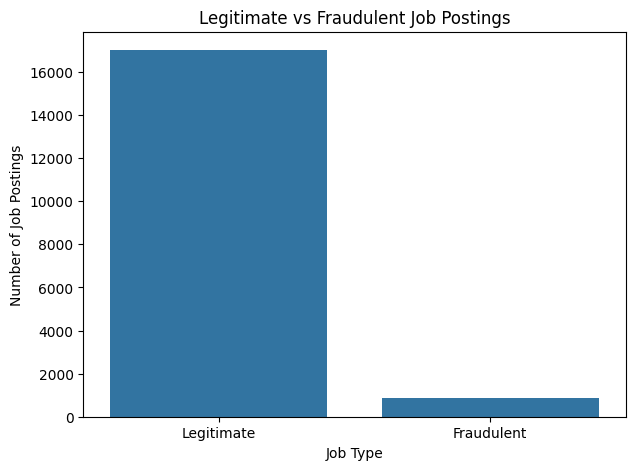

In [14]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='fraudulent',
    order=['f', 't']
)

plt.title('Legitimate vs Fraudulent Job Postings')
plt.xlabel('Job Type')
plt.ylabel('Number of Job Postings')

plt.xticks(
    [0, 1],
    ['Legitimate', 'Fraudulent']
)

plt.show()

In [15]:
pd.set_option('display.max_colwidth', 150)

df[['title', 'company_profile', 'description', 'requirements', 'fraudulent']].head(5)

,title,company_profile,description,requirements,fraudulent
0,Marketing Intern,"<h3>We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them ...","<p>Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and curated recipe hub, is currently interviewing ful...",<ul>\r\n<li>Experience with content management systems a major plus (any blogging counts!)</li>\r\n<li>Familiar with the Food52 editorial voice an...,f
1,Customer Service - Cloud Video Production,"<h3>90 Seconds, the worlds Cloud Video Production Service.</h3>\r\n<p>90 Seconds is the worlds Cloud Video Production Service enabling brands and ...",<p>Organised - Focused - Vibrant - Awesome!<br><br>Do you have a passion for customer service? Slick typing skills? Maybe Account Management? ...A...,"<p><b>What we expect from you:</b></p>\r\n<p>Your key responsibility will be to communicate with the client, 90 Seconds team and freelance communi...",f
2,Commissioning Machinery Assistant (CMA),"<h3></h3>\r\n<p>Valor Services provides Workforce Solutions that meet the needs of companies across the Private Sector, with a special focus on th...","<p>Our client, located in Houston, is actively seeking an experienced Commissioning Machinery Assistant that possesses strong supervisory skills a...",<ul>\r\n<li>Implement pre-commissioning and commissioning procedures for rotary equipment.</li>\r\n<li>Execute all activities with subcontractor’s...,f
3,Account Executive - Washington DC,<p>Our passion for improving quality of life through geography is at the heart of everything we do. Esri’s geographic information system (GIS) te...,<p><b>THE COMPANY: ESRI – Environmental Systems Research Institute</b></p>\r\n<p>Our passion for improving quality of life through geography is at...,"<ul>\r\n<li>\r\n<b>EDUCATION: </b>Bachelor’s or Master’s in GIS, business administration, or a related field, or equivalent work experience, depen...",f
4,Bill Review Manager,"<p>SpotSource Solutions LLC is a Global Human Capital Management Consulting firm headquartered in Miami, Florida. Founded in January 2012, SpotSou...","<p><b>JOB TITLE:</b> Itemization Review Manager</p>\r\n<p><b>LOCATION:</b> Fort Worth, TX<b> ...","<p><b>QUALIFICATIONS:</b></p>\r\n<ul>\r\n<li>RN license in the State of Texas</li>\r\n<li>Diploma or Bachelors of Science in Nursing, required</li...",f


In [16]:
fraud_jobs = df[df['fraudulent'] == 't']

fraud_jobs[
    ['title', 'company_profile', 'description', 'requirements']
].head(5)

,title,company_profile,description,requirements
98,IC&E Technician,"<p> <img src=""#URL_a9fa980073b093916a3b892dbcc0c2f8ad7ce8a6ee981f6...","<p><b><img src=""#URL_ae07dc35dfe86ebc1101b48eec77574871f2ba0daaf971ad3f2e2246bee5b31d#""></b></p>\r\n<p></p>\r\n<p></p>\r\n<p><b>IC&amp;E Technicia...","<h3><b>Qualifications</b></h3>\r\n<p><b>Knowledge, Skills &amp; Abilities:</b></p>\r\n<p> A high school diploma or GED is required. Must have a va..."
144,Forward Cap.,NaN,<p>The group has raised a fund for the purchase of homes in the Southeast. The student on this project will help them build their investments from...,NaN
173,Technician Instrument & Controls,"<p><img src=""#URL_044fce3aa43cecf7fd7f1fd790ab4a1f937f268e543cd5f08b2dbd6e52143406#""></p>\r\n<p>Edison International and Refined Resources have pa...","<p><b>Technician Instrument &amp; Controls</b><br><b>Location </b>Deweyville, TX<b><br>Location Name: </b>NRG Cottonwood Energy<b><br>Category: </...",<p><b>JOB QUALIFICATIONS</b><br><br>-Ability to understand procedures and instructions specific to the area of assignment as would be acquired in ...
180,Sales Executive,NaN,<p>Sales Executive</p>,<p>Sales Executive</p>
215,IC&E Technician Mt Poso,"<p> <img src=""#URL_a9fa980073b093916a3b892dbcc0c2f8ad7ce8a6ee981f6...","<p><b><img src=""#URL_ae07dc35dfe86ebc1101b48eec77574871f2ba0daaf971ad3f2e2246bee5b31d#""></b></p>\r\n<p></p>\r\n<p></p>\r\n<p><b>IC&amp;E Technicia...","<h3><b> Qualifications</b></h3>\r\n<p><b>Knowledge, Skills &amp; Abilities:</b></p>\r\n<p> A high school diploma or GED is required. Must have a v..."


In [17]:
df_clean = df.copy()

print("Original dataset:", df.shape)
print("Working dataset:", df_clean.shape)

Original dataset: (17880, 18)
Working dataset: (17880, 18)


In [18]:
print(df_clean['in_balanced_dataset'].value_counts())

in_balanced_dataset
f    16980
t      900
Name: count, dtype: int64


In [19]:
text_columns = [
    'title',
    'company_profile',
    'description',
    'requirements',
    'benefits'
]

print(text_columns)

['title', 'company_profile', 'description', 'requirements', 'benefits']


In [20]:
for col in text_columns:
    df_clean[col] = df_clean[col].fillna('')

print(df_clean[text_columns].isnull().sum())

title              0
company_profile    0
description        0
requirements       0
benefits           0
dtype: int64


In [21]:
!pip install beautifulsoup4 -q

In [22]:
from bs4 import BeautifulSoup

def remove_html(text):
    return BeautifulSoup(str(text), "html.parser").get_text(" ")

In [23]:
for col in text_columns:
    df_clean[col] = df_clean[col].apply(remove_html)

In [24]:
for col in text_columns:
    df_clean[col] = df_clean[col].str.lower()

In [25]:
import re

def remove_urls(text):
    return re.sub(r'http\S+|www\S+', ' ', text)

for col in text_columns:
    df_clean[col] = df_clean[col].apply(remove_urls)

In [26]:
def clean_spaces(text):
    return re.sub(r'\s+', ' ', text).strip()

for col in text_columns:
    df_clean[col] = df_clean[col].apply(clean_spaces)

In [27]:
df_clean['combined_text'] = (
    df_clean['title'] + ' ' +
    df_clean['company_profile'] + ' ' +
    df_clean['description'] + ' ' +
    df_clean['requirements'] + ' ' +
    df_clean['benefits']
)

In [28]:
df_clean['fraudulent'] = df_clean['fraudulent'].map({
    'f': 0,
    't': 1
})

In [29]:
print("Dataset shape:", df_clean.shape)

print("\nMissing combined text:")
print(df_clean['combined_text'].isnull().sum())

print("\nTarget distribution:")
print(df_clean['fraudulent'].value_counts())

print("\nTarget missing values:")
print(df_clean['fraudulent'].isnull().sum())

Dataset shape: (17880, 19)

Missing combined text:
0

Target distribution:
fraudulent
0    17014
1      866
Name: count, dtype: int64

Target missing values:
0


In [30]:
!pip install nltk -q

In [31]:
import nltk

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK setup completed!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


NLTK setup completed!


In [32]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [33]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

print("Stopwords:", list(stop_words)[:10])

Stopwords: ['and', 'myself', 'ourselves', 'why', 'about', 'our', 'out', "it'd", 'will', 'wouldn']


In [34]:
def preprocess_text(text):

    # Tokenization
    tokens = word_tokenize(text)

    # Keep alphabetic words and remove stopwords
    tokens = [
        word for word in tokens
        if word.isalpha() and word not in stop_words
    ]

    # Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return ' '.join(tokens)

In [36]:
import nltk

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')
nltk.download('punkt_tab')

print("NLTK resources downloaded successfully!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


NLTK resources downloaded successfully!


In [37]:
sample_text = df_clean['combined_text'].iloc[0]

print("BEFORE:")
print(sample_text[:1000])

print("\nAFTER:")
print(preprocess_text(sample_text)[:1000])

BEFORE:
marketing intern we're food52, and we've created a groundbreaking and award-winning cooking site. we support, connect, and celebrate home cooks, and give them everything they need in one place. we have a top editorial, business, and engineering team. we're focused on using technology to find new and better ways to connect people around their specific food interests, and to offer them superb, highly curated information about food and cooking. we attract the most talented home cooks and contributors in the country; we also publish well-known professionals like mario batali, gwyneth paltrow, and danny meyer. and we have partnerships with whole foods market and random house. food52 has been named the best food website by the james beard foundation and iacp, and has been featured in the new york times, npr, pando daily, techcrunch, and on the today show. we're located in chelsea, in new york city. food52, a fast-growing, james beard award-winning online food community and crowd-sour

In [38]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("All NLTK resources downloaded successfully!")

All NLTK resources downloaded successfully!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [40]:
df_clean['processed_text'] = df_clean['combined_text'].apply(preprocess_text)

print("NLP preprocessing completed!")
print("Number of processed job postings:", len(df_clean))

NLP preprocessing completed!
Number of processed job postings: 17880


In [41]:
df_clean[['combined_text', 'processed_text', 'fraudulent']].head(3)

,combined_text,processed_text,fraudulent
0,"marketing intern we're food52, and we've created a groundbreaking and award-winning cooking site. we support, connect, and celebrate home cooks, a...",marketing intern created groundbreaking cooking site support connect celebrate home cook give everything need one place top editorial business eng...,0
1,"customer service - cloud video production 90 seconds, the worlds cloud video production service. 90 seconds is the worlds cloud video production s...",customer service cloud video production second world cloud video production service second world cloud video production service enabling brand age...,0
2,"commissioning machinery assistant (cma) valor services provides workforce solutions that meet the needs of companies across the private sector, wi...",commissioning machinery assistant cma valor service provides workforce solution meet need company across private sector special focus oil gas indu...,0


In [42]:
print("Missing processed text:")
print(df_clean['processed_text'].isnull().sum())

Missing processed text:
0


In [43]:
from sklearn.model_selection import train_test_split

# Input feature
X = df_clean['processed_text']

# Target
y = df_clean['fraudulent']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 14304
Testing samples: 3576

Training class distribution:
fraudulent
0    13611
1      693
Name: count, dtype: int64

Testing class distribution:
fraudulent
0    3403
1     173
Name: count, dtype: int64


In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (14304, 5000)
Testing TF-IDF shape: (3576, 5000)


In [45]:
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))

Number of TF-IDF features: 5000


In [46]:
feature_names = tfidf.get_feature_names_out()

print("\nFirst 50 TF-IDF features:")
print(feature_names[:50])


First 50 TF-IDF features:
['abc' 'abc supply' 'ability' 'ability adapt' 'ability build'
 'ability communicate' 'ability develop' 'ability effectively'
 'ability handle' 'ability learn' 'ability lift' 'ability manage'
 'ability meet' 'ability prioritize' 'ability quickly' 'ability required'
 'ability take' 'ability travel' 'ability understand' 'ability use'
 'ability work' 'ability write' 'able' 'able communicate' 'able perform'
 'able work' 'abroad' 'abroad conversational' 'abroad help' 'abroad play'
 'absolutely' 'academic' 'accelerate' 'accept' 'acceptable' 'acceptance'
 'access' 'accessible' 'accommodation' 'accommodation willingness'
 'accomplish' 'accordance' 'according' 'accordingly' 'account'
 'account executive' 'account management' 'account manager'
 'account payable' 'accountability']


In [47]:
import pandas as pd

tfidf_sample = pd.DataFrame(
    X_train_tfidf[:5].toarray(),
    columns=feature_names
)

tfidf_sample.iloc[:, :20]

,abc,abc supply,ability,ability adapt,ability build,ability communicate,ability develop,ability effectively,ability handle,ability learn,ability lift,ability manage,ability meet,ability prioritize,ability quickly,ability required,ability take,ability travel,ability understand,ability use
0,0.000000,0.000000,0.023650,0.0,0.0,0.058135,0.0,0.00000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.000000,0.000000,0.076311,0.0,0.0,0.000000,0.0,0.03705,0.0,0.0,0.046344,0.0,0.039809,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.000000,0.000000,0.017514,0.0,0.0,0.043051,0.0,0.00000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.183114,0.126327,0.034720,0.0,0.0,0.000000,0.0,0.00000,0.0,0.0,0.052714,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.00000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [48]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("X_train_tfidf shape:", X_train_tfidf.shape)
print("X_test_tfidf shape:", X_test_tfidf.shape)

X_train shape: (14304,)
X_test shape: (3576,)
X_train_tfidf shape: (14304, 5000)
X_test_tfidf shape: (3576, 5000)


In [49]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# Train the model
model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [50]:
# Make predictions on the test data
y_pred = model.predict(X_test_tfidf)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

Predictions generated successfully!
Number of predictions: 3576


In [51]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

Model Evaluation Results
------------------------
Accuracy : 0.9667
Precision: 0.608
Recall   : 0.8786
F1-Score : 0.7187


Confusion Matrix:
[[3305   98]
 [  21  152]]


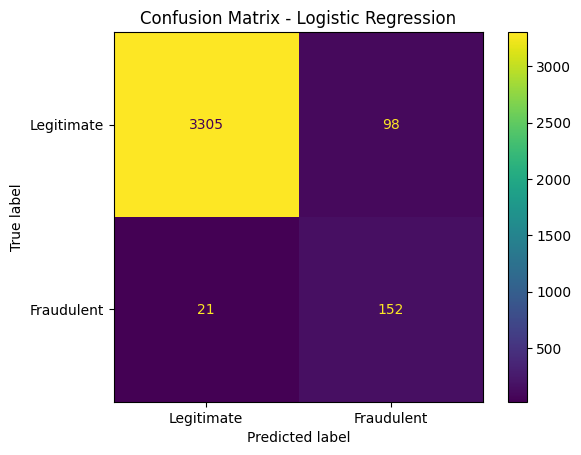

In [52]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Legitimate', 'Fraudulent']
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [53]:
from sklearn.metrics import classification_report

print("Classification Report")
print("======================")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Legitimate', 'Fraudulent']
))

Classification Report
              precision    recall  f1-score   support

  Legitimate       0.99      0.97      0.98      3403
  Fraudulent       0.61      0.88      0.72       173

    accuracy                           0.97      3576
   macro avg       0.80      0.92      0.85      3576
weighted avg       0.98      0.97      0.97      3576



In [54]:
from sklearn.svm import LinearSVC

# Create Linear SVM model
svm_model = LinearSVC(
    class_weight='balanced',
    random_state=42
)

# Train the model
svm_model.fit(X_train_tfidf, y_train)

print("Linear SVM model trained successfully!")

Linear SVM model trained successfully!


In [55]:
# Make predictions using Linear SVM
y_pred_svm = svm_model.predict(X_test_tfidf)

print("SVM predictions generated successfully!")
print("Number of predictions:", len(y_pred_svm))

SVM predictions generated successfully!
Number of predictions: 3576


In [56]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluate Linear SVM
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall = recall_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)

print("Linear SVM Evaluation Results")
print("-----------------------------")
print("Accuracy :", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1-Score :", round(svm_f1, 4))

Linear SVM Evaluation Results
-----------------------------
Accuracy : 0.9835
Precision: 0.8167
Recall   : 0.8497
F1-Score : 0.8329


In [57]:
print("Linear SVM Classification Report")
print("=================================")

print(classification_report(
    y_test,
    y_pred_svm,
    target_names=['Legitimate', 'Fraudulent']
))

Linear SVM Classification Report
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99      3403
  Fraudulent       0.82      0.85      0.83       173

    accuracy                           0.98      3576
   macro avg       0.90      0.92      0.91      3576
weighted avg       0.98      0.98      0.98      3576



SVM Confusion Matrix:
[[3370   33]
 [  26  147]]


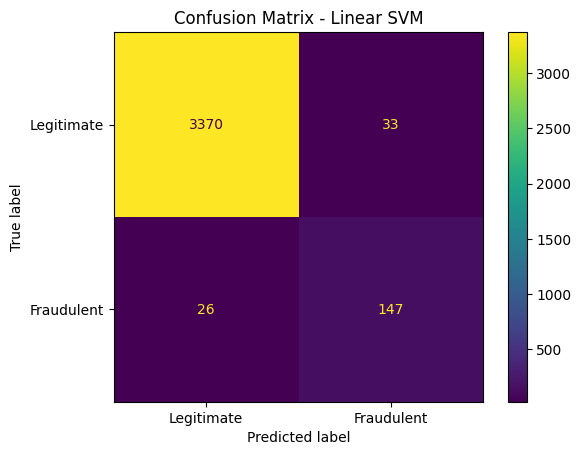

In [58]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# SVM confusion matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

print("SVM Confusion Matrix:")
print(cm_svm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=['Legitimate', 'Fraudulent']
)

disp.plot()
plt.title("Confusion Matrix - Linear SVM")
plt.show()

In [59]:
# Model Comparison

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Linear SVM'],
    'Accuracy': [0.9667, 0.9835],
    'Precision': [0.6080, 0.8167],
    'Recall': [0.8786, 0.8497],
    'F1-Score': [0.7187, 0.8329]
})

print("Model Comparison")
print("================")
print(comparison)

Model Comparison
                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression    0.9667     0.6080  0.8786    0.7187
1           Linear SVM    0.9835     0.8167  0.8497    0.8329


In [60]:
from sklearn.naive_bayes import MultinomialNB

# Create Multinomial Naive Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

print("Multinomial Naive Bayes model trained successfully!")

Multinomial Naive Bayes model trained successfully!


In [61]:
# Generate predictions
nb_pred = nb_model.predict(X_test_tfidf)

print("Predictions generated successfully!")
print("Number of predictions:", len(nb_pred))

Predictions generated successfully!
Number of predictions: 3576


In [62]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate evaluation metrics
nb_accuracy = accuracy_score(y_test, nb_pred)
nb_precision = precision_score(y_test, nb_pred)
nb_recall = recall_score(y_test, nb_pred)
nb_f1 = f1_score(y_test, nb_pred)

print("Multinomial Naive Bayes Evaluation Results")
print("------------------------------------------")
print("Accuracy :", round(nb_accuracy, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1-Score :", round(nb_f1, 4))

Multinomial Naive Bayes Evaluation Results
------------------------------------------
Accuracy : 0.9701
Precision: 1.0
Recall   : 0.3815
F1-Score : 0.5523


In [63]:
from sklearn.metrics import classification_report

print("Multinomial Naive Bayes Classification Report")
print("==============================================")

print(classification_report(
    y_test,
    nb_pred,
    target_names=['Legitimate', 'Fraudulent']
))

Multinomial Naive Bayes Classification Report
              precision    recall  f1-score   support

  Legitimate       0.97      1.00      0.98      3403
  Fraudulent       1.00      0.38      0.55       173

    accuracy                           0.97      3576
   macro avg       0.98      0.69      0.77      3576
weighted avg       0.97      0.97      0.96      3576



Multinomial Naive Bayes Confusion Matrix:
[[3403    0]
 [ 107   66]]


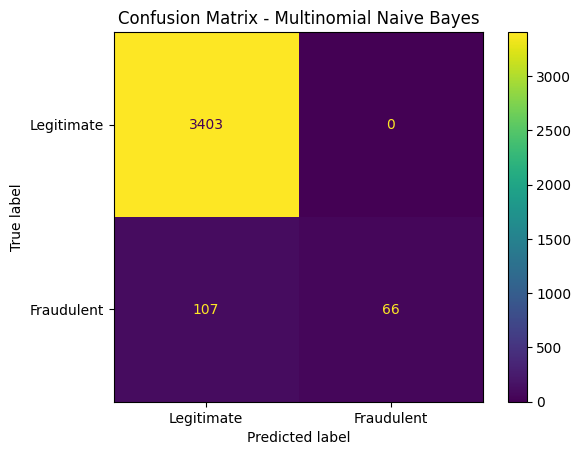

In [64]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Naive Bayes confusion matrix
cm_nb = confusion_matrix(y_test, nb_pred)

print("Multinomial Naive Bayes Confusion Matrix:")
print(cm_nb)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=['Legitimate', 'Fraudulent']
)

disp.plot()
plt.title("Confusion Matrix - Multinomial Naive Bayes")
plt.show()

In [65]:
import pandas as pd
import matplotlib.pyplot as plt

comparison_df = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Multinomial Naive Bayes',
        'Linear SVM'
    ],
    'Accuracy': [
        0.9667,
        0.9701,
        0.9835
    ],
    'Precision': [
        0.6080,
        1.0000,
        0.8167
    ],
    'Recall': [
        0.8786,
        0.3815,
        0.8497
    ],
    'F1-Score': [
        0.7187,
        0.5523,
        0.8329
    ]
})

print(comparison_df.round(4).to_string(index=False))

                  Model  Accuracy  Precision  Recall  F1-Score
    Logistic Regression    0.9667     0.6080  0.8786    0.7187
Multinomial Naive Bayes    0.9701     1.0000  0.3815    0.5523
             Linear SVM    0.9835     0.8167  0.8497    0.8329


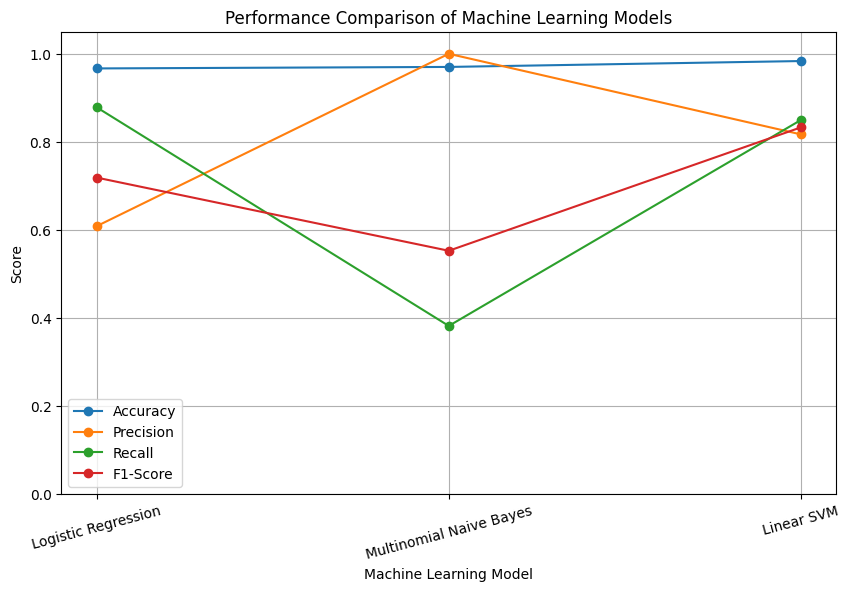

In [66]:
import matplotlib.pyplot as plt

models = comparison_df['Model']

plt.figure(figsize=(10, 6))

plt.plot(models, comparison_df['Accuracy'], marker='o', label='Accuracy')
plt.plot(models, comparison_df['Precision'], marker='o', label='Precision')
plt.plot(models, comparison_df['Recall'], marker='o', label='Recall')
plt.plot(models, comparison_df['F1-Score'], marker='o', label='F1-Score')

plt.title('Performance Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Model')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.xticks(rotation=15)
plt.show()

In [67]:
comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9667,0.6080,0.8786,0.7187
1,Multinomial Naive Bayes,0.9701,1.0000,0.3815,0.5523
2,Linear SVM,0.9835,0.8167,0.8497,0.8329


In [68]:
# Final Model Selection

print("=" * 70)
print("FINAL MODEL SELECTION")
print("=" * 70)

print("\nSelected Model: LINEAR SVM")

print("\nReason for Selection:")
print("• Highest Accuracy: 98.35%")
print("• Highest F1-Score: 83.29%")
print("• Precision: 81.67%")
print("• Recall: 84.97%")

print("\nComparison:")
print("-" * 70)
print("Logistic Regression     → Accuracy: 96.67% | F1-Score: 71.87%")
print("Multinomial Naive Bayes → Accuracy: 97.01% | F1-Score: 55.23%")
print("Linear SVM              → Accuracy: 98.35% | F1-Score: 83.29%")

print("\nConclusion:")
print("Linear SVM was selected as the final model because it provides")
print("the best overall balance between precision, recall, and F1-score.")
print("It achieved the highest accuracy and F1-score among the evaluated models.")

print("=" * 70)

FINAL MODEL SELECTION

Selected Model: LINEAR SVM

Reason for Selection:
• Highest Accuracy: 98.35%
• Highest F1-Score: 83.29%
• Precision: 81.67%
• Recall: 84.97%

Comparison:
----------------------------------------------------------------------
Logistic Regression     → Accuracy: 96.67% | F1-Score: 71.87%
Multinomial Naive Bayes → Accuracy: 97.01% | F1-Score: 55.23%
Linear SVM              → Accuracy: 98.35% | F1-Score: 83.29%

Conclusion:
Linear SVM was selected as the final model because it provides
the best overall balance between precision, recall, and F1-score.
It achieved the highest accuracy and F1-score among the evaluated models.


In [77]:
# Test the final model on a new job posting

new_job = """
Marketing Manager needed for a growing company.
The candidate should have experience in digital marketing,
social media management, campaign planning and brand strategy.
The company offers a competitive salary and professional growth opportunities.
Interested candidates can apply through the official company website.
"""

# Convert the new job posting into TF-IDF features
new_job_tfidf = tfidf.transform([new_job])

# Make prediction using the final Linear SVM model
prediction = final_model.predict(new_job_tfidf)[0]

# Display result
if prediction == 1:
    print("Prediction: FRAUDULENT JOB POSTING")
else:
    print("Prediction: LEGITIMATE JOB POSTING")

Prediction: LEGITIMATE JOB POSTING


In [78]:
# Test a suspicious job posting

fraud_job = """
URGENT! Work from home and earn $5000 per week.
No experience required. Get hired immediately!
You must pay a small registration fee to secure your position.
Send your bank account details and personal information to complete registration.
Limited positions available. Act now!
"""

# Convert to TF-IDF
fraud_job_tfidf = tfidf.transform([fraud_job])

# Predict
fraud_prediction = final_model.predict(fraud_job_tfidf)[0]

# Display result
if fraud_prediction == 1:
    print("Prediction: FRAUDULENT JOB POSTING")
else:
    print("Prediction: LEGITIMATE JOB POSTING")

Prediction: FRAUDULENT JOB POSTING


In [79]:
# Third practical test case

job_3 = """
Work from home data entry job.
Earn up to $4000 every month with flexible working hours.
No interview or previous experience required.
You need to purchase our starter kit for $199 before beginning work.
Contact us through WhatsApp and send your ID proof to get started.
"""

# Convert to TF-IDF
job_3_tfidf = tfidf.transform([job_3])

# Predict using final Linear SVM
prediction_3 = final_model.predict(job_3_tfidf)[0]

# Display result
if prediction_3 == 1:
    print("Prediction: FRAUDULENT JOB POSTING")
else:
    print("Prediction: LEGITIMATE JOB POSTING")

Prediction: FRAUDULENT JOB POSTING


In [71]:
# Hyperparameter Tuning - Creating Training and Validation Sets

from sklearn.model_selection import train_test_split

# Split the original training data into training and validation sets
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training samples   :", len(X_train_sub))
print("Validation samples :", len(X_val))
print("Test samples       :", len(X_test))

print("\nTraining class distribution:")
print(y_train_sub.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

Training samples   : 11443
Validation samples : 2861
Test samples       : 3576

Training class distribution:
fraudulent
0    10889
1      554
Name: count, dtype: int64

Validation class distribution:
fraudulent
0    2722
1     139
Name: count, dtype: int64


In [72]:
# TF-IDF transformation for Hyperparameter Tuning

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_tuning = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_sub_tfidf = tfidf_tuning.fit_transform(X_train_sub)
X_val_tfidf = tfidf_tuning.transform(X_val)

print("Training TF-IDF shape   :", X_train_sub_tfidf.shape)
print("Validation TF-IDF shape :", X_val_tfidf.shape)

Training TF-IDF shape   : (11443, 5000)
Validation TF-IDF shape : (2861, 5000)


In [73]:
# Hyperparameter Tuning using Validation Set

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

C_values = [0.01, 0.1, 1, 10, 100]

tuning_results = []

for c in C_values:

    svm = LinearSVC(
        C=c,
        class_weight='balanced',
        random_state=42,
        max_iter=10000
    )

    svm.fit(X_train_sub_tfidf, y_train_sub)

    val_pred = svm.predict(X_val_tfidf)

    tuning_results.append({
        'C': c,
        'Accuracy': accuracy_score(y_val, val_pred),
        'Precision': precision_score(y_val, val_pred),
        'Recall': recall_score(y_val, val_pred),
        'F1-Score': f1_score(y_val, val_pred)
    })

tuning_df = pd.DataFrame(tuning_results)

print("Hyperparameter Tuning Results:")
print(tuning_df.round(4).to_string(index=False))

Hyperparameter Tuning Results:
     C  Accuracy  Precision  Recall  F1-Score
  0.01    0.9381     0.4301  0.8417    0.5693
  0.10    0.9633     0.5859  0.8345    0.6884
  1.00    0.9790     0.7926  0.7698    0.7810
 10.00    0.9783     0.8182  0.7122    0.7615
100.00    0.9787     0.8305  0.7050    0.7626


In [74]:
# Final Model Training After Hyperparameter Tuning

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Train final model using the complete training set
final_model = LinearSVC(
    C=1.0,
    class_weight='balanced',
    random_state=42,
    max_iter=10000
)

final_model.fit(X_train_tfidf, y_train)

# Evaluate ONCE on the untouched test set
final_pred = final_model.predict(X_test_tfidf)

final_accuracy = accuracy_score(y_test, final_pred)
final_precision = precision_score(y_test, final_pred)
final_recall = recall_score(y_test, final_pred)
final_f1 = f1_score(y_test, final_pred)

print("=" * 65)
print("FINAL MODEL - TEST SET PERFORMANCE")
print("=" * 65)

print("Model       : Linear SVM")
print("Optimal C   : 1.0")
print(f"Accuracy    : {final_accuracy:.4f} ({final_accuracy*100:.2f}%)")
print(f"Precision   : {final_precision:.4f} ({final_precision*100:.2f}%)")
print(f"Recall      : {final_recall:.4f} ({final_recall*100:.2f}%)")
print(f"F1-Score    : {final_f1:.4f} ({final_f1*100:.2f}%)")

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_pred,
    target_names=['Legitimate', 'Fraudulent']
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_pred))

print("=" * 65)

FINAL MODEL - TEST SET PERFORMANCE
Model       : Linear SVM
Optimal C   : 1.0
Accuracy    : 0.9835 (98.35%)
Precision   : 0.8167 (81.67%)
Recall      : 0.8497 (84.97%)
F1-Score    : 0.8329 (83.29%)

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99      3403
  Fraudulent       0.82      0.85      0.83       173

    accuracy                           0.98      3576
   macro avg       0.90      0.92      0.91      3576
weighted avg       0.98      0.98      0.98      3576


Confusion Matrix:
[[3370   33]
 [  26  147]]


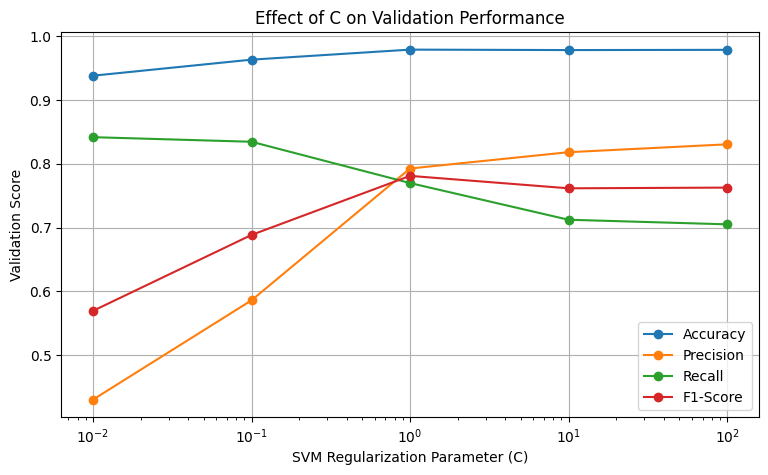

In [75]:
# Figure 4: Effect of C on Validation Performance

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    tuning_df['C'],
    tuning_df['Accuracy'],
    marker='o',
    label='Accuracy'
)

plt.plot(
    tuning_df['C'],
    tuning_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    tuning_df['C'],
    tuning_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    tuning_df['C'],
    tuning_df['F1-Score'],
    marker='o',
    label='F1-Score'
)

plt.xscale('log')
plt.xlabel('SVM Regularization Parameter (C)')
plt.ylabel('Validation Score')
plt.title('Effect of C on Validation Performance')
plt.legend()
plt.grid(True)
plt.show()

In [76]:
# Table III: Hyperparameter Tuning Results

table_iii = tuning_df.copy()

# Convert scores to percentages
table_iii['Accuracy'] = table_iii['Accuracy'] * 100
table_iii['Precision'] = table_iii['Precision'] * 100
table_iii['Recall'] = table_iii['Recall'] * 100
table_iii['F1-Score'] = table_iii['F1-Score'] * 100

# Format values with 2 decimal places
table_iii['Accuracy'] = table_iii['Accuracy'].map(lambda x: f"{x:.2f}%")
table_iii['Precision'] = table_iii['Precision'].map(lambda x: f"{x:.2f}%")
table_iii['Recall'] = table_iii['Recall'].map(lambda x: f"{x:.2f}%")
table_iii['F1-Score'] = table_iii['F1-Score'].map(lambda x: f"{x:.2f}%")

print("TABLE III")
print("EFFECT OF SVM REGULARIZATION PARAMETER ON VALIDATION PERFORMANCE")
print("-" * 70)

print(table_iii.to_string(index=False))

TABLE III
EFFECT OF SVM REGULARIZATION PARAMETER ON VALIDATION PERFORMANCE
----------------------------------------------------------------------
     C Accuracy Precision Recall F1-Score
  0.01   93.81%    43.01% 84.17%   56.93%
  0.10   96.33%    58.59% 83.45%   68.84%
  1.00   97.90%    79.26% 76.98%   78.10%
 10.00   97.83%    81.82% 71.22%   76.15%
100.00   97.87%    83.05% 70.50%   76.26%
